<a href="https://colab.research.google.com/github/kevin-sun-shi/kevin-/blob/main/Instrument_Robustness_Colab_HF_Fast.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Robustness of Instrument Recognition Models Under Noisy Conditions (Fast HF Version)
零微调（Zero-shot）端到端评估实验：通过 Hugging Face 秒加载纯净乐器数据集，对比 **AST (Transformer)** 与 **PANNs Cnn14 (CNN)** 在不同信噪比（SNR）背景噪声下的乐器识别鲁棒性。

In [1]:
# Cell 1：安装依赖与高速下载数据（无需等待大压缩包）
!pip install -q transformers torchaudio panns-inference datasets soundfile librosa scikit-learn matplotlib seaborn tqdm

# 下载 ESC-50 环境噪声数据集 (~600MB，约 20 秒完成)
!wget -q --show-progress https://github.com/karolpiczak/ESC-50/archive/master.zip -O esc50.zip
!unzip -q -o esc50.zip

print("✅ 环境与背景噪声数据集准备就绪！")

esc50.zip           100%[===================>] 615.78M  51.5MB/s    in 17s     
✅ 环境与背景噪声数据集准备就绪！


In [14]:
import os
import glob
import random
import subprocess
import numpy as np
import torch
import librosa
import pandas as pd
from tqdm import tqdm

# 固定随机种子保证实验可复现
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"当前运行设备: {device}")

# 1. 高速下载并解压官方 IRMAS 真实乐器数据集 (~600MB，16 线程约 15 秒完成)
if not os.path.exists("IRMAS-TrainingData"):
    print("正在使用 16 线程高速下载官方 IRMAS 真实乐器数据集 (~600MB)...")
    subprocess.run("apt-get -qq install -y aria2", shell=True, check=True)
    subprocess.run(
        'aria2c -x 16 -s 16 -k 1M "https://zenodo.org/records/1290750/files/IRMAS-TrainingData.zip?download=1" -o irmas_train.zip',
        shell=True, check=True
    )
    subprocess.run("unzip -q -o irmas_train.zip", shell=True, check=True)
    print("✅ 官方 IRMAS 真实乐器数据集下载并解压完成！")

# IRMAS 11 种标准乐器缩写
IRMAS_CLASSES = ['cel', 'cla', 'flu', 'gac', 'gel', 'org', 'pia', 'sax', 'tru', 'vio', 'voi']

# 将预训练模型的 AudioSet 527 类标签映射到 IRMAS 11 类乐器
AUDIOSET_TO_IRMAS = {
    'cel': ['Cello'],
    'cla': ['Clarinet'],
    'flu': ['Flute'],
    'gac': ['Acoustic guitar'],
    'gel': ['Electric guitar'],
    'org': ['Organ', 'Electronic organ', 'Hammond organ'],
    'pia': ['Piano', 'Electric piano'],
    'sax': ['Saxophone'],
    'tru': ['Trumpet'],
    'vio': ['Violin, fiddle'],
    'voi': ['Singing', 'Male singing', 'Female singing', 'Choir', 'Vocal music']
}

# 2. 按文件夹读取真实的 3 秒单主乐器录音
all_samples = []
for inst in IRMAS_CLASSES:
    inst_wavs = sorted(glob.glob(f"IRMAS-TrainingData/{inst}/*.wav"))
    for w in inst_wavs:
        all_samples.append((w, inst))

# 随机抽取 300 条真实录音进行评估（保证 11 种乐器均匀覆盖；想跑全量可注释掉下面这行）
eval_samples = random.sample(all_samples, min(300, len(all_samples)))
print(f"✅ Cell 2 完成：成功加载 {len(eval_samples)} 条真实单主乐器测试样本（全库共 {len(all_samples)} 条）。")

# 3. 收集所有 ESC-50 环境噪声文件
noise_wavs = sorted(glob.glob("ESC-50-master/audio/*.wav"))
print(f"✅ 成功加载 {len(noise_wavs)} 条环境背景噪声样本。")

# 4. 核心功能：动态计算 RMS 能量并按目标 SNR 混合噪声
def mix_audio_with_snr(clean_audio, noise_audio, snr_db):
    if snr_db is None:  # Clean 组不加噪
        return clean_audio

    # 确保噪声长度与纯净音频一致（不够则循环拼接，太长则随机截取）
    if len(noise_audio) < len(clean_audio):
        repeat_times = int(np.ceil(len(clean_audio) / len(noise_audio)))
        noise_audio = np.tile(noise_audio, repeat_times)
    start_idx = random.randint(0, len(noise_audio) - len(clean_audio))
    noise_segment = noise_audio[start_idx : start_idx + len(clean_audio)]

    # 计算均方根能量 (RMS)
    rms_clean = np.sqrt(np.mean(clean_audio ** 2)) + 1e-8
    rms_noise = np.sqrt(np.mean(noise_segment ** 2)) + 1e-8

    # 根据目标 SNR (dB) 计算噪声缩放系数
    target_rms_noise = rms_clean / (10 ** (snr_db / 20.0))
    scaled_noise = noise_segment * (target_rms_noise / rms_noise)

    mixed = clean_audio + scaled_noise
    # 防止削波失真 (Clipping)
    max_val = np.max(np.abs(mixed))
    if max_val > 1.0:
        mixed = mixed / max_val
    return mixed

当前运行设备: cuda
正在使用 16 线程高速下载官方 IRMAS 真实乐器数据集 (~600MB)...
✅ 官方 IRMAS 真实乐器数据集下载并解压完成！
✅ Cell 2 完成：成功加载 300 条真实单主乐器测试样本（全库共 6705 条）。
✅ 成功加载 2000 条环境背景噪声样本。


In [15]:
from transformers import AutoFeatureExtractor, ASTForAudioClassification
from panns_inference import AudioTagging, labels as panns_labels
from sklearn.metrics import accuracy_score, f1_score

# --- 加载模型 1: Audio Spectrogram Transformer (AST) ---
print("正在加载 AST 预训练模型...")
ast_model_name = "MIT/ast-finetuned-audioset-10-10-0.4593"
ast_extractor = AutoFeatureExtractor.from_pretrained(ast_model_name)
ast_model = ASTForAudioClassification.from_pretrained(ast_model_name).to(device)
ast_model.eval()

# 构建 AST 的类别索引映射
ast_id2label = ast_model.config.id2label
ast_label2id = {v: k for k, v in ast_id2label.items()}
ast_irmas_indices = {
    inst: [ast_label2id[lbl] for lbl in lbls if lbl in ast_label2id]
    for inst, lbls in AUDIOSET_TO_IRMAS.items()
}

# --- 加载模型 2: PANNs (Cnn14) ---
print("正在加载 PANNs (Cnn14) 预训练模型...")
panns_model = AudioTagging(checkpoint_path=None, device=device)
panns_label2id = {lbl: idx for idx, lbl in enumerate(panns_labels)}
panns_irmas_indices = {
    inst: [panns_label2id[lbl] for lbl in lbls if lbl in panns_label2id]
    for inst, lbls in AUDIOSET_TO_IRMAS.items()
}

# --- 运行多信噪比梯度评估 ---
SNR_LEVELS = [None, 20, 10, 0, -5]  # None 代表原始 Clean 音频
results = []
predictions_at_0db = {"y_true": [], "ast_pred": [], "panns_pred": []}

# 预加载配对好的 3 秒真实乐器录音与随机背景噪声
preloaded_data = []
for wav_path, label in tqdm(eval_samples, desc="预加载真实测试音频"):
    y_32k, _ = librosa.load(wav_path, sr=32000, mono=True)
    y_32k = y_32k[:32000 * 3]
    noise_path = random.choice(noise_wavs)
    n_32k, _ = librosa.load(noise_path, sr=32000, mono=True)
    preloaded_data.append((y_32k, n_32k, label))

for snr in SNR_LEVELS:
    snr_name = "Clean" if snr is None else f"{snr}dB"
    y_true, ast_preds, panns_preds = [], [], []

    with torch.no_grad():
        for y_32k, n_32k, label in tqdm(preloaded_data, desc=f"正在评估 [{snr_name}]"):
            # 1. 动态混合噪声
            mixed_32k = mix_audio_with_snr(y_32k, n_32k, snr)

            # 2. PANNs 推理 (输入为 32kHz 波形)
            clipwise_output, _ = panns_model.inference(mixed_32k[None, :])
            panns_probs = clipwise_output[0]
            panns_scores = {
                inst: max([panns_probs[idx] for idx in idxs])
                for inst, idxs in panns_irmas_indices.items()
            }
            panns_pred = max(panns_scores, key=panns_scores.get)

            # 3. AST 推理 (下采样至 16kHz 提取 Log-Mel 频谱图)
            mixed_16k = librosa.resample(mixed_32k, orig_sr=32000, target_sr=16000)
            inputs = ast_extractor(mixed_16k, sampling_rate=16000, return_tensors="pt").to(device)
            logits = ast_model(**inputs).logits
            ast_probs = torch.sigmoid(logits)[0].cpu().numpy()
            ast_scores = {
                inst: max([ast_probs[idx] for idx in idxs])
                for inst, idxs in ast_irmas_indices.items()
            }
            ast_pred = max(ast_scores, key=ast_scores.get)

            y_true.append(label)
            panns_preds.append(panns_pred)
            ast_preds.append(ast_pred)

    # 保存 0dB 下的预测结果用于后续画混淆矩阵
    if snr == 0:
        predictions_at_0db = {"y_true": y_true, "ast_pred": ast_preds, "panns_pred": panns_preds}

    # 计算准确率与 Macro F1
    results.append({
        "SNR": snr_name,
        "AST_Acc": accuracy_score(y_true, ast_preds) * 100,
        "AST_F1": f1_score(y_true, ast_preds, average="macro") * 100,
        "PANNs_Acc": accuracy_score(y_true, panns_preds) * 100,
        "PANNs_F1": f1_score(y_true, panns_preds, average="macro") * 100,
    })

df_results = pd.DataFrame(results)
print("\n📊 真实乐器数据集实验结果汇总表：")
print(df_results.to_string(index=False))

正在加载 AST 预训练模型...


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

正在加载 PANNs (Cnn14) 预训练模型...
Checkpoint path: /root/panns_data/Cnn14_mAP=0.431.pth
GPU number: 1


正在评估 [-5dB]: 100%|██████████| 300/300 [00:30<00:00,  9.81it/s]


📊 真实乐器数据集实验结果汇总表：
  SNR   AST_Acc    AST_F1  PANNs_Acc  PANNs_F1
Clean 68.000000 67.102717  70.666667 69.248376
 20dB 67.666667 66.892959  68.333333 66.415593
 10dB 62.000000 60.945670  62.666667 60.370459
  0dB 55.333333 51.976833  50.333333 47.137162
 -5dB 53.333333 51.084608  44.000000 40.182855


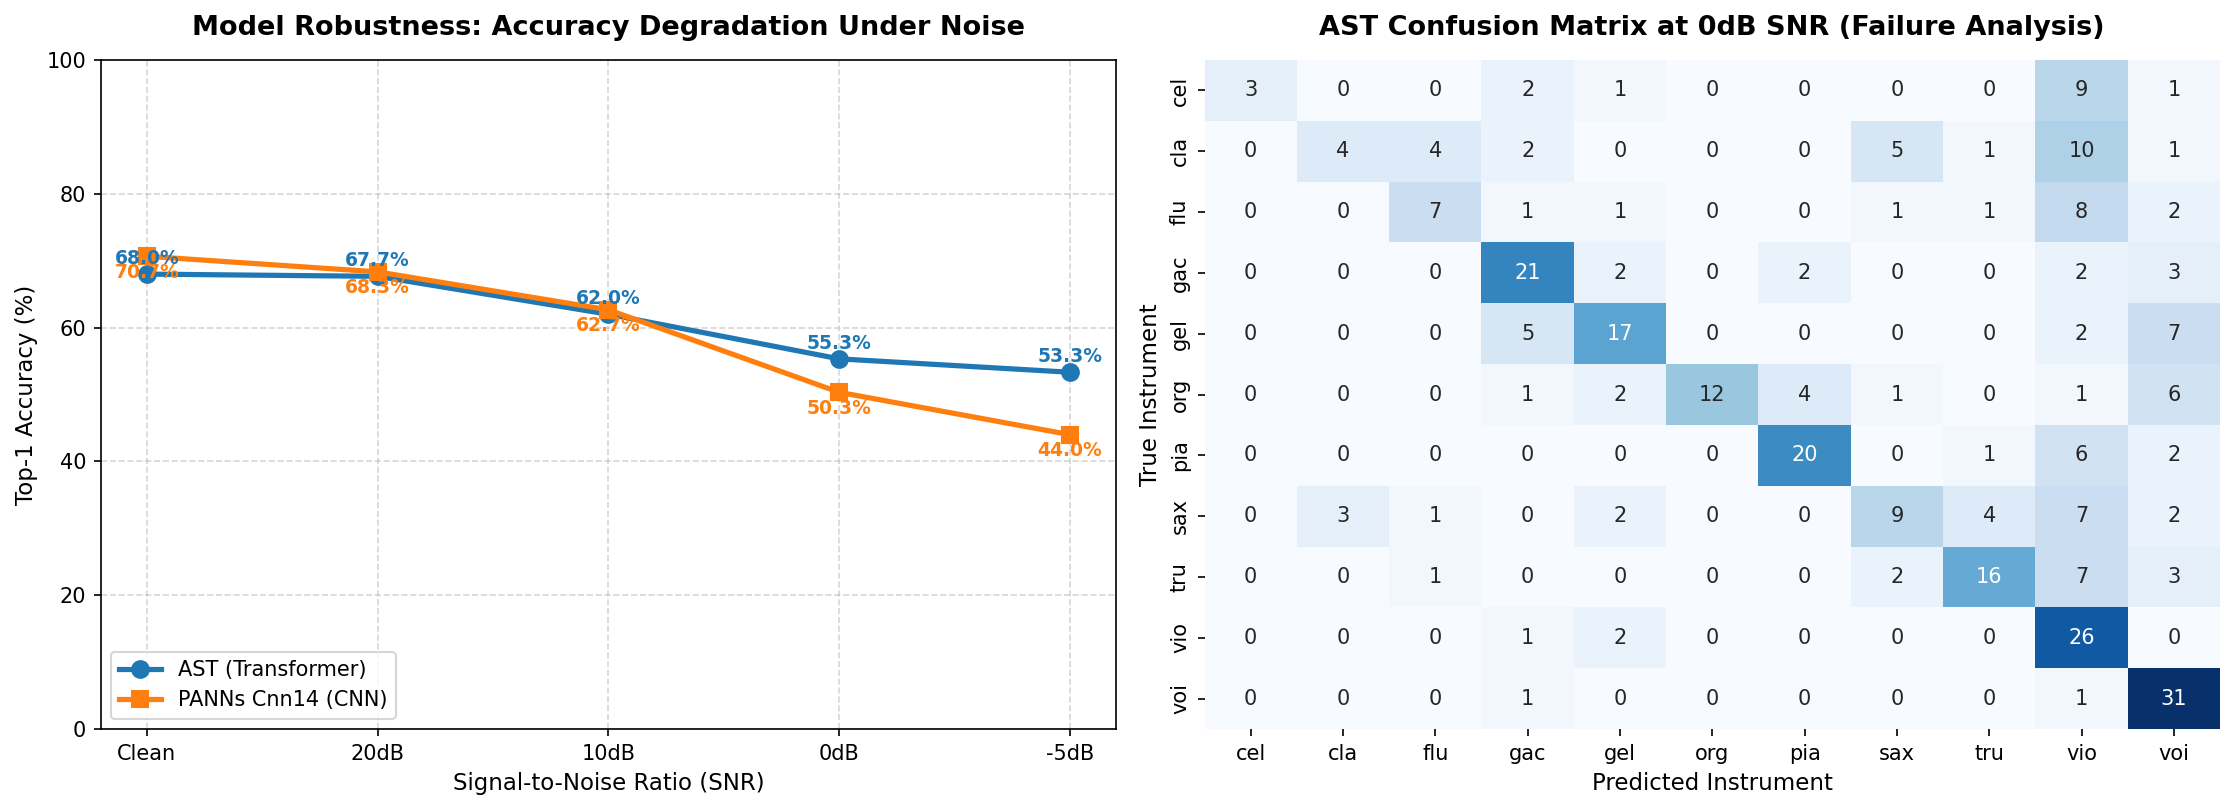

✅ 图表已保存为 robustness_results.png，可直接右键下载放入 PPT！


In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

plt.rcParams['figure.dpi'] = 150
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# --- 图 1: AST vs PANNs 准确率随信噪比衰减曲线 ---
ax1 = axes[0]
ax1.plot(df_results["SNR"], df_results["AST_Acc"], marker='o', linewidth=2.5, markersize=8, label="AST (Transformer)", color="#1f77b4")
ax1.plot(df_results["SNR"], df_results["PANNs_Acc"], marker='s', linewidth=2.5, markersize=8, label="PANNs Cnn14 (CNN)", color="#ff7f0e")

# 标注具体百分比数值
for i, row in df_results.iterrows():
    ax1.annotate(f"{row['AST_Acc']:.1f}%", (row['SNR'], row['AST_Acc'] + 1.5), ha='center', fontsize=9, color="#1f77b4", fontweight='bold')
    ax1.annotate(f"{row['PANNs_Acc']:.1f}%", (row['SNR'], row['PANNs_Acc'] - 3.2), ha='center', fontsize=9, color="#ff7f0e", fontweight='bold')

ax1.set_title("Model Robustness: Accuracy Degradation Under Noise", fontsize=13, fontweight='bold', pad=12)
ax1.set_xlabel("Signal-to-Noise Ratio (SNR)", fontsize=11)
ax1.set_ylabel("Top-1 Accuracy (%)", fontsize=11)
ax1.set_ylim(0, 100)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(fontsize=10, loc="lower left")

# --- 图 2: AST 在 0dB 强噪声下的乐器混淆矩阵 ---
ax2 = axes[1]
cm = confusion_matrix(predictions_at_0db["y_true"], predictions_at_0db["ast_pred"], labels=IRMAS_CLASSES)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=IRMAS_CLASSES, yticklabels=IRMAS_CLASSES, ax=ax2, cbar=False)
ax2.set_title("AST Confusion Matrix at 0dB SNR (Failure Analysis)", fontsize=13, fontweight='bold', pad=12)
ax2.set_xlabel("Predicted Instrument", fontsize=11)
ax2.set_ylabel("True Instrument", fontsize=11)

plt.tight_layout()
plt.savefig("robustness_results.png", dpi=300)
plt.show()
print("✅ 图表已保存为 robustness_results.png，可直接右键下载放入 PPT！")